# 🎯 Sistem Analisis Sentimen — Nowhere Experience Batam
ANALISIS SENTIMEN TERHADAP PROMOSI NOWHERE EXPERIENCE DI MEDIA SOSIAL MENGGUNAKAN METODE NAIVE BAYES

**Algoritma:** Multinomial Naive Bayes  
**Objek Analisis:** Nowhere Experience Batam (Escape Room)  
**Kelas Sentimen:** Positif, Negatif, Netral  

Pipeline: Scraping → Preprocessing → TF-IDF → Training Naive Bayes → Evaluasi → Prediksi → Visualisasi

In [1]:
!pip install sastrawi apify-client wordcloud -q
import subprocess, sys, json, urllib.request
subprocess.run([sys.executable, "-m", "pip", "install", "sastrawi", "apify-client", "wordcloud", "-q"], capture_output=True)

import pandas as pd, numpy as np, re, string, random, warnings, os, time
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from apify_client import ApifyClient
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
random.seed(42); np.random.seed(42)

# ========== KONFIGURASI ==========
APIFY_API_TOKEN = "apify_api_ZHtFZubhyjtvjCPs3BcxWEEHOUA4nm2yH28Z"

TIKTOK_URLS = [
    "https://www.tiktok.com/@nowhere.exp/video/7568406904481795346",
    "https://www.tiktok.com/@nowhere.exp/photo/7640791803347668244",
    "https://www.tiktok.com/@nowhere.exp/video/7571426892478205200",
]
INSTAGRAM_URLS = [
    "https://www.instagram.com/reel/DSAFybMEk5o/",
    "https://www.instagram.com/reel/DQ6huoTkWK5/",
]

print("=" * 60)
print("✅ Semua library berhasil di-import & dikonfigurasi")
print("=" * 60)
print(f"\n📱 TikTok URLs ({len(TIKTOK_URLS)}):")
for i, u in enumerate(TIKTOK_URLS, 1): print(f"   {i}. {u}")
print(f"\n📷 Instagram URLs ({len(INSTAGRAM_URLS)}):")
for i, u in enumerate(INSTAGRAM_URLS, 1): print(f"   {i}. {u}")
print("=" * 60)

# ========== HELPER: AMBIL DATASET ID (6 METODE + REST API FALLBACK) ==========
def get_dataset_id(run, api_token):
    """
    Robust extractor untuk dataset_id dari Apify Run object.
    Mencoba 6 metode lokal, lalu fallback ke REST API langsung.
    """
    # Metode 1: Direct property
    try:
        did = run.defaultDatasetId
        if did: return did
    except Exception:
        pass
    # Metode 2: Dict-style access
    try:
        did = run["defaultDatasetId"]
        if did: return did
    except Exception:
        pass
    # Metode 3: Pydantic v2 model_dump()
    try:
        did = run.model_dump().get("defaultDatasetId")
        if did: return did
    except Exception:
        pass
    # Metode 4: Pydantic v1 dict()
    try:
        did = run.dict().get("defaultDatasetId")
        if did: return did
    except Exception:
        pass
    # Metode 5: vars() / __dict__
    try:
        did = vars(run).get("defaultDatasetId")
        if did: return did
    except Exception:
        pass
    # Metode 6: Cari atribut apapun yang mengandung 'dataset'
    try:
        for attr in dir(run):
            if 'dataset' in attr.lower():
                val = getattr(run, attr, None)
                if val and isinstance(val, str) and len(val) > 5:
                    return val
    except Exception:
        pass

    # ===== FALLBACK: REST API LANGSUNG =====
    print("  ⚠️ Run object tidak bisa diakses, mencoba REST API langsung...")
    try:
        # Ambil run ID dengan berbagai cara
        run_id = None
        for getter in [lambda: run.id, lambda: run._id, lambda: run.runId]:
            try:
                rid = getter()
                if rid and isinstance(rid, str):
                    run_id = rid
                    break
            except Exception:
                continue

        if not run_id:
            print("  ❌ Tidak bisa mendapatkan run ID")
            return None

        print(f"  📡 Mengambil dataset_id via REST API untuk run {run_id}...")
        url = f"https://api.apify.com/v2/actor-runs/{run_id}"
        req = urllib.request.Request(url)
        req.add_header("Authorization", f"Bearer {api_token}")
        with urllib.request.urlopen(req, timeout=30) as resp:
            data = json.loads(resp.read().decode())
            did = data.get("data", {}).get("defaultDatasetId")
            if did:
                print(f"  ✅ Berhasil dapat dataset_id dari REST API: {did}")
                return did
    except Exception as e:
        print(f"  ❌ REST API gagal: {e}")

    return None

# ========== SCRAPING TIKTOK (Actor: BDec00yAmCm1QbMEI) ==========
def scrape_tiktok_comments(urls, api_token, comments_per_post=100):
    if not api_token or api_token.strip() == "<YOUR_API_TOKEN>":
        print("❌ Error: API token belum diisi!"); return []
    client = ApifyClient(api_token)
    run_input = {
        "postURLs": urls,
        "commentsPerPost": comments_per_post,
    }
    print("\n" + "=" * 60)
    print("🚀 MEMULAI SCRAPING KOMENTAR TIKTOK")
    print("=" * 60)
    print(f"  Actor            : BDec00yAmCm1QbMEI")
    print(f"  Jumlah URL       : {len(urls)}")
    print(f"  Comments per post: {comments_per_post}")
    print("-" * 60)
    try:
        run = client.actor("BDec00yAmCm1QbMEI").call(run_input=run_input)
        dataset_id = get_dataset_id(run, api_token)
        if not dataset_id:
            raise Exception("Tidak bisa mendapatkan dataset_id")
        comments = [item for item in client.dataset(dataset_id).iterate_items()]
        print(f"✅ Berhasil mengambil {len(comments)} komentar TikTok!")
        print("=" * 60)
        return comments
    except Exception as e:
        err_msg = str(e)
        if "Free Plan" in err_msg or "LIMITED_PERMISSIONS" in err_msg:
            print("❌ Actor TikTok tidak mendukung Free Plan via API.")
            print("   Solusi: Upgrade ke plan berbayar di https://apify.com/pricing")
            print("   Atau jalankan actor langsung di Apify Console, lalu simpan hasilnya sebagai CSV.")
        else:
            print(f"❌ Error saat scraping TikTok: {e}")
        print("=" * 60)
        return []

# ========== SCRAPING INSTAGRAM (Actor: AJB5X52e9Q5ZTR3Ie) ==========
def scrape_instagram_comments(urls, api_token, max_comments=1000):
    if not api_token or api_token.strip() == "<YOUR_API_TOKEN>":
        print("❌ Error: API token belum diisi!"); return []
    client = ApifyClient(api_token)
    run_input = {"urls": urls, "maxComments": max_comments}
    print("\n" + "=" * 60)
    print("🚀 MEMULAI SCRAPING KOMENTAR INSTAGRAM")
    print("=" * 60)
    print(f"  Actor        : AJB5X52e9Q5ZTR3Ie")
    print(f"  Jumlah URL   : {len(urls)}")
    print(f"  Max comments : {max_comments}")
    print("-" * 60)
    try:
        run = client.actor("AJB5X52e9Q5ZTR3Ie").call(run_input=run_input)
        dataset_id = get_dataset_id(run, api_token)
        if not dataset_id:
            raise Exception("Tidak bisa mendapatkan dataset_id")
        comments = [item for item in client.dataset(dataset_id).iterate_items()]
        print(f"✅ Berhasil mengambil {len(comments)} komentar Instagram!")
        print("=" * 60)
        return comments
    except Exception as e:
        err_msg = str(e)
        if "Free Plan" in err_msg or "LIMITED_PERMISSIONS" in err_msg:
            print("❌ Actor Instagram tidak mendukung Free Plan via API.")
            print("   Solusi 1: Upgrade ke plan berbayar di https://apify.com/pricing")
            print("   Solusi 2: Jalankan actor di Apify Console, download hasilnya.")
            print("   Solusi 3: Simpan komentar manual sebagai CSV dengan kolom 'text'.")
        else:
            print(f"❌ Error saat scraping Instagram: {e}")
        print("=" * 60)
        return []

# ========== KONVERSI KE DATAFRAME ==========
def convert_tiktok_to_df(comments):
    if not comments: return pd.DataFrame()
    data = []
    for c in comments:
        data.append({
            "platform": "TikTok",
            "text": c.get("text", c.get("commentText", c.get("comment", ""))),
            "author": c.get("author", c.get("authorUsername", c.get("username", c.get("nickname", "")))),
            "likes": c.get("likes", c.get("likesCount", c.get("diggCount", 0))),
            "created_at": c.get("createdAt", c.get("createTime", c.get("timestamp", ""))),
            "post_url": c.get("videoUrl", c.get("postUrl", c.get("webVideoUrl", ""))),
            "is_reply": c.get("isReply", c.get("replyToCommentId", None) is not None),
            "raw_data": c,
        })
    df = pd.DataFrame(data)
    print(f"📊 TikTok: {len(df)} komentar dikonversi ke DataFrame")
    return df

def convert_instagram_to_df(comments):
    if not comments: return pd.DataFrame()
    data = []
    for c in comments:
        data.append({
            "platform": "Instagram",
            "text": c.get("comment", c.get("text", "")),
            "author": c.get("comment_user", c.get("username", c.get("ownerUsername", ""))),
            "likes": c.get("likes_number", c.get("likesCount", 0)),
            "created_at": c.get("comment_date", c.get("timestamp", "")),
            "post_url": c.get("post_url", c.get("url", "")),
            "is_reply": False,
            "replies_count": c.get("replies_number", 0),
            "raw_data": c,
        })
    df = pd.DataFrame(data)
    print(f"📊 Instagram: {len(df)} komentar dikonversi ke DataFrame")
    return df

# ========== EKSEKUSI SCRAPING ==========
tiktok_raw = scrape_tiktok_comments(TIKTOK_URLS, APIFY_API_TOKEN, comments_per_post=100)
df_tiktok = convert_tiktok_to_df(tiktok_raw)

instagram_raw = scrape_instagram_comments(INSTAGRAM_URLS, APIFY_API_TOKEN, max_comments=1000)
df_instagram = convert_instagram_to_df(instagram_raw)

df_social = pd.concat([df_tiktok, df_instagram], ignore_index=True)

print("\n" + "=" * 60)
print("📋 RINGKASAN DATA SCRAPING")
print("=" * 60)
print(f"  TikTok    : {len(df_tiktok)} komentar")
print(f"  Instagram : {len(df_instagram)} komentar")
print(f"  Total     : {len(df_social)} komentar")
if len(df_social) > 0:
    print(f"\n  Distribusi per platform:\n{df_social['platform'].value_counts().to_string()}")
    print(f"\n  📝 5 Sampel Komentar:")
    print(df_social[["platform", "text", "author", "likes"]].head().to_string(index=False))
else:
    print("\n  ⚠️ Tidak ada data berhasil di-scrape.")
    print("  Jika kena limitasi Free Plan, sediakan file CSV manual dengan kolom 'text'.")
if len(df_social) > 0:
    df_social.to_csv("hasil_scraping_sosmed.csv", index=False, encoding="utf-8-sig")
    print(f"\n  💾 Disimpan ke: hasil_scraping_sosmed.csv")
print("=" * 60)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.4/149.4 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 83.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.1/331.1 kB 13.2 MB/s eta 0:00:00
✅ Semua library berhasil di-import & dikonfigurasi

📱 TikTok URLs (3):
   1. https://www.tiktok.com/@nowhere.exp/video/7568406904481795346
   2. https://www.tiktok.com/@nowhere.exp/photo/7640791803347668244
   3. https://www.tiktok.com/@nowhere.exp/video/7571426892478205200

📷 Instagram URLs (2):
   1. https://www.instagram.com/reel/DSAFybMEk5o/
   2. https://www.instagram.com/reel/DQ6huoTkWK5/

🚀 MEMULAI SCRAPING KOMENTAR TIKTOK
  Actor            : BDec00yAmCm1QbMEI
  Jumlah URL       : 3
  Comments per post: 100
------------------------------------------------------------


[apify.tiktok-comments-scraper runId:GOdKPk4LHcgyKE6hW] -> Status: RUNNING, Message: 
[apify.tiktok-comments-scraper runId:GOdKPk4LHcgyKE6hW] -> 2026-07-23T13:08:05.558Z ACTOR: Pulling container image of build shEYNW7woHucdH7oC from registry.
[apify.tiktok-comments-scraper runId:GOdKPk4LHcgyKE6hW] -> 2026-07-23T13:08:05.560Z ACTOR: Creating container.
[apify.tiktok-comments-scraper runId:GOdKPk4LHcgyKE6hW] -> 2026-07-23T13:08:05.592Z ACTOR: Starting container.
[apify.tiktok-comments-scraper runId:GOdKPk4LHcgyKE6hW] -> 2026-07-23T13:08:05.592Z ACTOR: Running under "LIMITED_PERMISSIONS".
[apify.tiktok-comments-scraper runId:GOdKPk4LHcgyKE6hW] -> 2026-07-23T13:08:05.767Z Running on architecture: x86_64
[apify.tiktok-comments-scraper runId:GOdKPk4LHcgyKE6hW] -> 2026-07-23T13:08:05.767Z Will run command: xvfb-run -a -s "-ac -screen 0 1920x1080x24+32 -nolisten tcp" /bin/bash -o pipefail -c bash -c "    java         --enable-native-access=ALL-UNNAMED         -cp classes-test:classes-main:lib/

✅ Berhasil mengambil 204 komentar TikTok!
📊 TikTok: 204 komentar dikonversi ke DataFrame

🚀 MEMULAI SCRAPING KOMENTAR INSTAGRAM
  Actor        : AJB5X52e9Q5ZTR3Ie
  Jumlah URL   : 2
  Max comments : 1000
------------------------------------------------------------


[apify.instagram-comments-scraper runId:jWB4oSEmjbtq6uzHk] -> Status: RUNNING, Message: 
[apify.instagram-comments-scraper runId:jWB4oSEmjbtq6uzHk] -> 2026-07-23T13:08:50.022Z ACTOR: Pulling container image of build aLYsCHa98MHvuvOi3 from registry.
[apify.instagram-comments-scraper runId:jWB4oSEmjbtq6uzHk] -> 2026-07-23T13:08:50.023Z ACTOR: Creating container.
[apify.instagram-comments-scraper runId:jWB4oSEmjbtq6uzHk] -> 2026-07-23T13:08:50.086Z ACTOR: Starting container.
[apify.instagram-comments-scraper runId:jWB4oSEmjbtq6uzHk] -> 2026-07-23T13:08:50.087Z ACTOR: Running under "LIMITED_PERMISSIONS".
[apify.instagram-comments-scraper runId:jWB4oSEmjbtq6uzHk] -> 2026-07-23T13:08:51.635Z INFO  System info {"apifyVersion":"3.5.2","apifyClientVersion":"2.20.0","crawleeVersion":"3.15.3","osType":"Linux","nodeVersion":"v20.20.2"}
[apify.instagram-comments-scraper runId:jWB4oSEmjbtq6uzHk] -> 2026-07-23T13:08:52.652Z INFO  Queueing post DQ6huoTkWK5 with media ID 3763468778530235065 and user ID

✅ Berhasil mengambil 31 komentar Instagram!
📊 Instagram: 31 komentar dikonversi ke DataFrame

📋 RINGKASAN DATA SCRAPING
  TikTok    : 204 komentar
  Instagram : 31 komentar
  Total     : 235 komentar

  Distribusi per platform:
platform
TikTok       204
Instagram     31

  📝 5 Sampel Komentar:
platform                                     text author  likes
  TikTok                 belakang BCA lebih seram           104
  TikTok serem gak ? ada garansi kalau gak serem?            72
  TikTok           nitip es nya jangan sampe cair           115
  TikTok    Tengok videonya aja dah merinding aku             4
  TikTok        Satu room bisa main berapa orang?             9

  💾 Disimpan ke: hasil_scraping_sosmed.csv


✅ Data dimuat: 235 komentar dari hasil_scraping_sosmed.csv
Jumlah stopword Sastrawi: 123

⏳ Memulai preprocessing...
✅ Preprocessing & pelabelan selesai!

Distribusi Label Sentimen:
sentimen
Netral     216
Positif     15
Negatif      4

CONTOH BEFORE / AFTER PREPROCESSING

--- Contoh 1 ---
BEFORE : film apa ini???
AFTER  : film apa
LABEL  : Netral

--- Contoh 2 ---
BEFORE : kalau bedua bisa gasi😔😔
AFTER  : kalau bedua gas
LABEL  : Netral

--- Contoh 3 ---
BEFORE : lebih takut kabel internet di gali 😂
AFTER  : lebih takut kabel internet gali
LABEL  : Netral

--- Contoh 4 ---
BEFORE : @🍪
AFTER  : 
LABEL  : Netral

--- Contoh 5 ---
BEFORE : Tengok videonya aja dah merinding aku
AFTER  : tengok video aja dah merinding aku
LABEL  : Netral


TF-IDF Matrix Shape: (235, 169)
Jumlah fitur: 169

10 Fitur paling diskriminatif:
     fitur     idf
        ah 5.36522
   apa nih 5.36522
      asli 5.36522
aku pernah 5.36522
     batas 5.36522
banget yaa 5.36522
     balek 5.36522
       ayo 5.36522
 

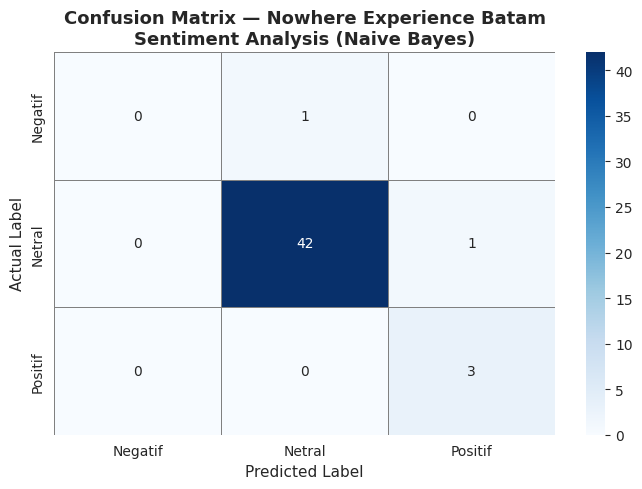


ANALISIS SINGKAT
  Kelas TERBAIK  : Netral  (F1 = 0.9767)
  Kelas TERBURUK : Negatif (F1 = 0.0000)
  Accuracy total   : 95.74%


In [2]:
# ========== LOAD DATA ==========
DATA_FILE = "hasil_scraping_sosmed.csv"
# FALLBACK: Jika scraping gagal, letakkan file CSV manual lalu ubah path:
# DATA_FILE = "komentar_manual.csv"

try:
    df_raw = pd.read_csv(DATA_FILE)
    if "text" not in df_raw.columns:
        text_col = [c for c in df_raw.columns if "text" in c.lower() or "komentar" in c.lower() or "comment" in c.lower()]
        if text_col:
            df = df_raw[[text_col[0]]].copy().rename(columns={text_col[0]: 'teks'})
        else:
            raise ValueError(f"Kolom 'text' tidak ditemukan. Kolom: {list(df_raw.columns)}")
    else:
        df = df_raw[['text']].copy().rename(columns={'text': 'teks'})
    df = df.dropna(subset=['teks'])
    df = df[df['teks'].astype(str).str.strip() != '']
    df = df.reset_index(drop=True)
    print(f"✅ Data dimuat: {len(df)} komentar dari {DATA_FILE}")
except FileNotFoundError:
    print(f"⚠️ File {DATA_FILE} tidak ditemukan.")
    print("   Pastikan scraping berhasil, atau sediakan file CSV manual.")
    df = pd.DataFrame(columns=['teks'])
except Exception as e:
    print(f"⚠️ Error loading data: {e}")
    df = pd.DataFrame(columns=['teks'])

if len(df) == 0:
    raise SystemExit("❌ Tidak ada data. Pipeline dihentikan.")

# ========== SETUP SASTRAWI ==========
stemmer = StemmerFactory().create_stemmer()
stopword_remover = StopWordRemoverFactory().create_stop_word_remover()
stopword_list = set(StopWordRemoverFactory().get_stop_words())
print(f"Jumlah stopword Sastrawi: {len(stopword_list)}")

# ========== KAMUS NORMALISASI & LEXICON ==========
slang_dict = {
    "bgt": "banget", "gak": "tidak", "ga": "tidak", "enggak": "tidak",
    "yg": "yang", "tp": "tapi", "dgn": "dengan", "jg": "juga",
    "udh": "sudah", "lg": "lagi", "krn": "karena", "smpe": "sampai",
    "bsa": "bisa", "bener": "benar", "bener2": "benar-benar",
    "mantep": "mantap", "bagusss": "bagus", "gpp": "tidak apa-apa",
    "worth it": "sepadan", "healing": "penyembuhan",
    "sih": "", "kok": "", "yah": "", "nah": "", "gitu": "", "dong": "",
    "kan": "", "deh": "", "lah": "", "ya": "", "loh": "", "tuh": ""
}
positive_lexicon = {
    "bagus", "keren", "seru", "menantang", "nyaman", "ramah", "helpful",
    "recommended", "worth", "sepadan", "senang", "solid", "sabar", "jelas",
    "estetik", "ketagihan", "mantap", "kreatif", "baik", "puas"
}
negative_lexicon = {
    "sulit", "bingung", "sempit", "panas", "mahal", "kecewa", "mengecewakan",
    "lama", "ribet", "gerah", "gelap", "sakit", "canggung", "berantakan",
    "rusak", "sia", "jelek", "bau", "kotor", "buruk", "susah", "lambat"
}

def label_with_lexicon(teks):
    words = teks.split()
    pos_score = sum(1 for w in words if w in positive_lexicon)
    neg_score = sum(1 for w in words if w in negative_lexicon)
    if pos_score > neg_score: return "Positif"
    elif neg_score > pos_score: return "Negatif"
    else: return "Netral"

def preprocessing_text(teks):
    if not isinstance(teks, str): return ""
    teks = teks.lower()
    teks = re.sub(r"http\S+|www\.\S+", " ", teks)
    teks = re.sub(r"@\w+", " ", teks)
    teks = re.sub(r"#\w+", " ", teks)
    teks = re.sub(r"\d+", " ", teks)
    teks = re.sub(r'(.)\1{2,}', r'\1', teks)
    teks = teks.translate(str.maketrans("", "", string.punctuation))
    teks = re.sub(r"[^a-z\s]", " ", teks)
    teks = re.sub(r"\s+", " ", teks).strip()
    words = teks.split()
    words = [slang_dict.get(w, w) for w in words]
    negation_words = ["tidak", "bukan", "kurang", "jangan", "tak", "gak", "ga"]
    i = 0
    while i < len(words) - 1:
        if words[i] in negation_words:
            words[i] = words[i] + "_" + words[i + 1]
            del words[i + 1]
        i += 1
    teks_joined = " ".join(words)
    teks_joined = stopword_remover.remove(teks_joined)
    teks_joined = stemmer.stem(teks_joined)
    teks_joined = re.sub(r"\s+", " ", teks_joined).strip()
    return teks_joined

# ========== EKSEKUSI PREPROCESSING ==========
print("\n⏳ Memulai preprocessing...")
df["teks_bersih"] = df["teks"].apply(preprocessing_text)
df["sentimen"] = df["teks_bersih"].apply(label_with_lexicon)
print("✅ Preprocessing & pelabelan selesai!")
print(f"\nDistribusi Label Sentimen:\n{df['sentimen'].value_counts().to_string()}")

print("\n" + "=" * 80)
print("CONTOH BEFORE / AFTER PREPROCESSING")
print("=" * 80)
for i, idx in enumerate(df.sample(min(5, len(df)), random_state=7).index, 1):
    print(f"\n--- Contoh {i} ---")
    print(f"BEFORE : {df.loc[idx, 'teks']}")
    print(f"AFTER  : {df.loc[idx, 'teks_bersih']}")
    print(f"LABEL  : {df.loc[idx, 'sentimen']}")
print("\n" + "=" * 80)

# ========== TF-IDF ==========
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
X_tfidf = vectorizer.fit_transform(df["teks_bersih"])
y = df["sentimen"].values
print(f"\nTF-IDF Matrix Shape: {X_tfidf.shape}")
print(f"Jumlah fitur: {len(vectorizer.get_feature_names_out())}")
feat_idf_df = pd.DataFrame({"fitur": vectorizer.get_feature_names_out(), "idf": vectorizer.idf_}).sort_values("idf", ascending=False).reset_index(drop=True)
print(f"\n10 Fitur paling diskriminatif:")
print(feat_idf_df.head(10).to_string(index=False))

# ========== SPLIT & TRAINING ==========
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.20, random_state=42, stratify=y)
print(f"\n{'=' * 60}")
print(f"PEMBAGIAN DATA: Train={X_train.shape[0]}, Test={X_test.shape[0]}")
print(f"{'=' * 60}")
print(f"Distribusi train:\n{pd.Series(y_train).value_counts().to_string()}")
print(f"\nDistribusi test:\n{pd.Series(y_test).value_counts().to_string()}")

model = MultinomialNB(alpha=0.1)
model.fit(X_train, y_train)
print(f"\n✅ Model MultinomialNB trained! Classes: {model.classes_}, Alpha: {model.alpha}")

# ========== EVALUASI ==========
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"\n{'=' * 60}")
print(f"EVALUASI MODEL — Accuracy: {acc:.4f} ({acc * 100:.2f}%)")
print(f"{'=' * 60}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

labels_order = list(model.classes_)
cm = confusion_matrix(y_test, y_pred, labels=labels_order)
cm_df = pd.DataFrame(cm, index=[f"Actual_{l}" for l in labels_order], columns=[f"Pred_{l}" for l in labels_order])
print(f"\nConfusion Matrix:\n{cm_df.to_string()}")

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_order, yticklabels=labels_order, cbar=True, linewidths=0.5, linecolor="gray")
plt.title("Confusion Matrix — Nowhere Experience Batam\nSentiment Analysis (Naive Bayes)", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("Actual Label", fontsize=11)
plt.tight_layout()
plt.show()

report_dict = classification_report(y_test, y_pred, output_dict=True)
f1_scores = {k: report_dict[k]["f1-score"] for k in labels_order}
best_class = max(f1_scores, key=f1_scores.get)
worst_class = min(f1_scores, key=f1_scores.get)
print(f"\n{'=' * 60}")
print(f"ANALISIS SINGKAT")
print(f"{'=' * 60}")
if len(set(f1_scores.values())) == 1:
    print(f"  Semua kelas F1-score sama: {f1_scores[best_class]:.4f}")
else:
    print(f"  Kelas TERBAIK  : {best_class}  (F1 = {f1_scores[best_class]:.4f})")
    print(f"  Kelas TERBURUK : {worst_class} (F1 = {f1_scores[worst_class]:.4f})")
print(f"  Accuracy total   : {acc * 100:.2f}%")
print(f"{'=' * 60}")

Sanity check predict_sentimen():
  Input : main di nowhere experience batam seru banget, puzzle menantang!
  Output: {'sentimen': 'Positif', 'confidence': 0.898, 'probabilities': {'Negatif': 0.0122, 'Netral': 0.0897, 'Positif': 0.898}, 'teks_bersih': 'main nowhere experience batam seru banget puzzle tantang'}

🌐 ANALISIS SENTIMEN KOMENTAR MEDIA SOSIAL (TIKTOK & INSTAGRAM)

📊 Total komentar dianalisis: 235
------------------------------------------------------------------------------------------
 No  Platform  Author  Likes                                                                                                    Teks                                                                         Teks Bersih Prediksi Label Lexicon  Confidence  P(Positif)  P(Negatif)  P(Netral)
  1    TikTok     NaN    104                                                                                belakang BCA lebih seram                                                            belakang bca lebih se

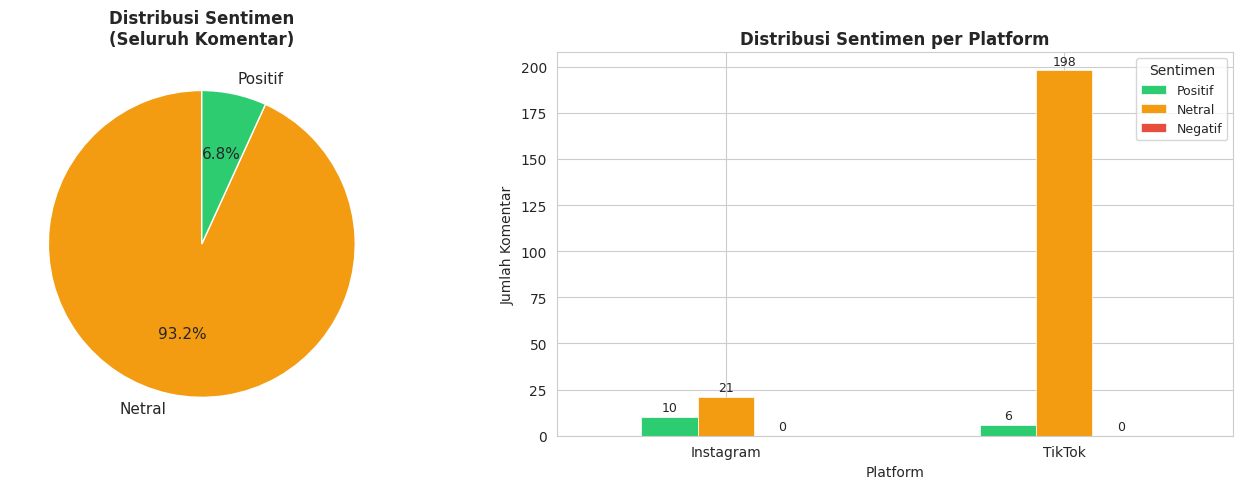

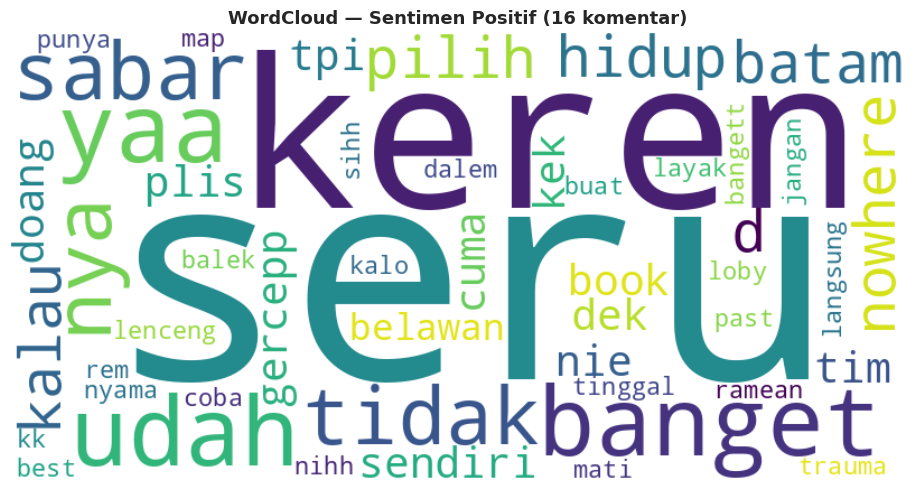

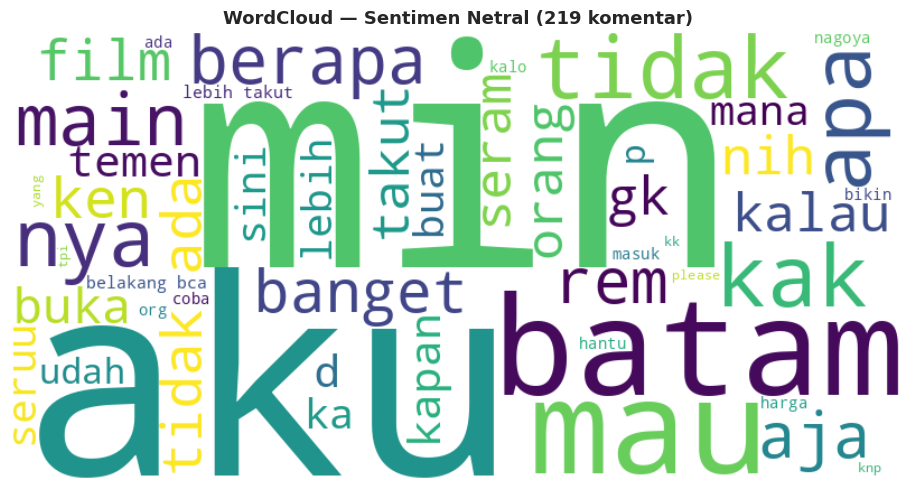


💾 Hasil analisis disimpan ke: hasil_analisis_sentimen_sosial.csv
✅ PIPELINE SELESAI


In [3]:
# ========== FUNGSI PREDIKSI ==========
def predict_sentimen(teks_input, model, vectorizer, stemmer, stopword_remover):
    teks_bersih = preprocessing_text(teks_input)
    vec = vectorizer.transform([teks_bersih])
    kelas_pred = model.predict(vec)[0]
    proba = model.predict_proba(vec)[0]
    classes = model.classes_
    probabilities = {str(cls): float(p) for cls, p in zip(classes, proba)}
    confidence = float(max(proba))
    return {
        "sentimen": str(kelas_pred), "confidence": round(confidence, 4),
        "probabilities": {k: round(v, 4) for k, v in probabilities.items()},
        "teks_bersih": teks_bersih
    }

demo = predict_sentimen("main di nowhere experience batam seru banget, puzzle menantang!", model, vectorizer, stemmer, stopword_remover)
print("Sanity check predict_sentimen():")
print(f"  Input : main di nowhere experience batam seru banget, puzzle menantang!")
print(f"  Output: {demo}\n")

# ========== ANALISIS SENTIMEN DATA SOCIAL MEDIA ==========
print("=" * 90)
print("🌐 ANALISIS SENTIMEN KOMENTAR MEDIA SOSIAL (TIKTOK & INSTAGRAM)")
print("=" * 90)

try:
    df_social = pd.read_csv("hasil_scraping_sosmed.csv")
except FileNotFoundError:
    df_social = pd.DataFrame()

if len(df_social) == 0:
    print("\n⚠️ Tidak ada data scraping. Menggunakan sampel dari dataset...")
    demo_texts = df["teks"].sample(min(10, len(df)), random_state=42).tolist()
    demo_platforms = ["Dataset"] * len(demo_texts)
    demo_authors = ["-"] * len(demo_texts)
    demo_likes = [0] * len(demo_texts)
else:
    demo_texts = df_social["text"].tolist()
    demo_platforms = df_social["platform"].tolist()
    demo_authors = df_social["author"].tolist()
    demo_likes = df_social["likes"].tolist()

hasil_social = []
for i, teks in enumerate(demo_texts):
    if not teks or not isinstance(teks, str): continue
    res = predict_sentimen(teks, model, vectorizer, stemmer, stopword_remover)
    hasil_social.append({
        "No": i + 1,
        "Platform": demo_platforms[i] if i < len(demo_platforms) else "-",
        "Author": demo_authors[i] if i < len(demo_authors) else "-",
        "Likes": demo_likes[i] if i < len(demo_likes) else 0,
        "Teks": teks[:100] + "..." if len(str(teks)) > 100 else teks,
        "Teks Bersih": res["teks_bersih"][:80] + "..." if len(res["teks_bersih"]) > 80 else res["teks_bersih"],
        "Prediksi": res["sentimen"],
        "Label Lexicon": label_with_lexicon(res["teks_bersih"]),
        "Confidence": res["confidence"],
        "P(Positif)": res["probabilities"].get("Positif", 0.0),
        "P(Negatif)": res["probabilities"].get("Negatif", 0.0),
        "P(Netral)": res["probabilities"].get("Netral", 0.0),
    })

hasil_df = pd.DataFrame(hasil_social)
print(f"\n📊 Total komentar dianalisis: {len(hasil_df)}")
print("-" * 90)
print(hasil_df.to_string(index=False))
print("-" * 90)

if len(df_social) > 0 and "platform" in df_social.columns:
    print("\n📈 RINGKASAN SENTIMEN PER PLATFORM:")
    print("-" * 60)
    for platform in df_social["platform"].unique():
        pf = hasil_df[hasil_df["Platform"] == platform]
        if len(pf) == 0: continue
        print(f"\n🔹 {platform} ({len(pf)} komentar):")
        print(pf["Prediksi"].value_counts().to_string())
        print(f"   Rata-rata confidence: {pf['Confidence'].mean():.4f}")
    print("-" * 60)

# ========== VISUALISASI DISTRIBUSI ==========
if len(hasil_df) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sentimen_counts = hasil_df["Prediksi"].value_counts()
    colors = {"Positif": "#2ecc71", "Negatif": "#e74c3c", "Netral": "#f39c12"}
    pie_colors = [colors.get(s, "#95a5a6") for s in sentimen_counts.index]
    axes[0].pie(sentimen_counts.values, labels=sentimen_counts.index, autopct='%1.1f%%', colors=pie_colors, startangle=90, textprops={'fontsize': 11})
    axes[0].set_title("Distribusi Sentimen\n(Seluruh Komentar)", fontsize=12, fontweight='bold')
    if len(df_social) > 0 and hasil_df["Platform"].nunique() > 1:
        pivot = hasil_df.groupby(["Platform", "Prediksi"]).size().unstack(fill_value=0)
        pivot = pivot.reindex(columns=["Positif", "Netral", "Negatif"], fill_value=0)
        pivot.plot(kind="bar", ax=axes[1], color=[colors.get(c, "#95a5a6") for c in pivot.columns], edgecolor="white", linewidth=0.5)
        axes[1].set_title("Distribusi Sentimen per Platform", fontsize=12, fontweight='bold')
        axes[1].set_xlabel("Platform", fontsize=10)
        axes[1].set_ylabel("Jumlah Komentar", fontsize=10)
        axes[1].legend(title="Sentimen", fontsize=9)
        axes[1].tick_params(axis='x', rotation=0)
        for container in axes[1].containers:
            axes[1].bar_label(container, fontsize=9, padding=2)
    else:
        axes[1].bar(sentimen_counts.index, sentimen_counts.values, color=[colors.get(s, "#95a5a6") for s in sentimen_counts.index], edgecolor="white", linewidth=0.5)
        axes[1].set_title("Jumlah Komentar per Sentimen", fontsize=12, fontweight='bold')
        axes[1].set_ylabel("Jumlah", fontsize=10)
        for i, (label, val) in enumerate(zip(sentimen_counts.index, sentimen_counts.values)):
            axes[1].text(i, val + 0.3, str(val), ha='center', fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ========== WORDCLOUD PER SENTIMEN ==========
if len(hasil_df) > 0:
    for sentimen_label in ["Positif", "Negatif", "Netral"]:
        subset = hasil_df[hasil_df["Prediksi"] == sentimen_label]
        if len(subset) == 0: continue
        text_combined = " ".join(subset["Teks Bersih"].dropna().astype(str).tolist())
        if not text_combined.strip(): continue
        wc = WordCloud(width=800, height=400, background_color="white", max_words=50, colormap="viridis", min_font_size=10).generate(text_combined)
        plt.figure(figsize=(10, 5))
        plt.imshow(wc, interpolation="bilinear")
        plt.axis("off")
        plt.title(f"WordCloud — Sentimen {sentimen_label} ({len(subset)} komentar)", fontsize=13, fontweight="bold")
        plt.tight_layout()
        plt.show()

if len(hasil_df) > 0:
    hasil_df.to_csv("hasil_analisis_sentimen_sosial.csv", index=False, encoding="utf-8-sig")
    print(f"\n💾 Hasil analisis disimpan ke: hasil_analisis_sentimen_sosial.csv")

print("=" * 90)
print("✅ PIPELINE SELESAI")
print("=" * 90)